# AIFS

This tutorial demonstrates how to download the ECMWF Open Data Artificial Intelligence IFS (AIFS). Recent and archived IFS and AIFS data is freely available from ECMWF in GRIB2 format.

- [ECMWF open data: real-time forecasts from IFS and AIFS](https://confluence.ecmwf.int/display/DAC/ECMWF+open+data%3A+real-time+forecasts+from+IFS+and+AIFS)
- [ECMWF Open-Data](https://www.ecmwf.int/en/forecasts/datasets/open-data)

### Model Types

ECMWF provides data for two different models

1. `model="ifs"` ECMWF Integrated Forecast System
1. `model="aifs"` ECMWF Artificial Intelligence Integrated Forecast System


Download and plot ECMWF AIFS model data.

> ⚠ AIFS GRIB files before **March 13, 2024**, seemed to be encoded incorrectly as they are read as a vector instead of a grid. I'm not sure how this data can be recovered or reshaped.


In [1]:
from herbie import Herbie

import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np

from herbie import paint
from herbie.toolbox import EasyMap, pc

In [29]:
H = Herbie("2024-06-11", model="aifs", product="oper", fxx=12)

H.grib, H.idx

✅ Found ┊ model=aifs ┊ product=oper ┊ 2024-Jun-11 00:00 UTC F12 ┊ GRIB2 @ azure ┊ IDX @ azure


('https://ai4edataeuwest.blob.core.windows.net/ecmwf/20240611/00z/aifs/0p25/oper/20240611000000-12h-oper-fc.grib2',
 'https://ai4edataeuwest.blob.core.windows.net/ecmwf/20240611/00z/aifs/0p25/oper/20240611000000-12h-oper-fc.index')

In [30]:
H.inventory(":t:850")

,grib_message,start_byte,end_byte,range,reference_time,valid_time,step,param,levelist,levtype,number,domain,expver,class,type,stream,search_this
32,33,25515811,26027206,25515811-26027206,2024-06-11,2024-06-11 12:00:00,0 days 12:00:00,t,850,pl,NaN,g,0001,ai,fc,oper,:t:850:pl:g:0001:ai:fc:oper


<xarray.Dataset> Size: 4MB
Dimensions:              (latitude: 721, longitude: 1440)
Coordinates:
    time                 datetime64[ns] 8B 2024-06-11
    step                 timedelta64[ns] 8B 12:00:00
    isobaricInhPa        float64 8B 850.0
  * latitude             (latitude) float64 6kB 90.0 89.75 89.5 ... -89.75 -90.0
  * longitude            (longitude) float64 12kB -180.0 -179.8 ... 179.5 179.8
    valid_time           datetime64[ns] 8B 2024-06-11T12:00:00
    gribfile_projection  object 8B None
Data variables:
    t                    (latitude, longitude) float32 4MB 271.1 271.1 ... 235.1
Attributes:
    GRIB_edition:            2
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    model:                   aifs
    product:                 oper
    description:             ECMWF Open Data - Artificial Inteligence Integra...
    remote_grib:             https://ai4edataeuwest.blob.core.windows.net/ecm...
    local_grib:              /home/blaylock/data/aifs/20240611/subset_f812da9...
    search:                  :t:850

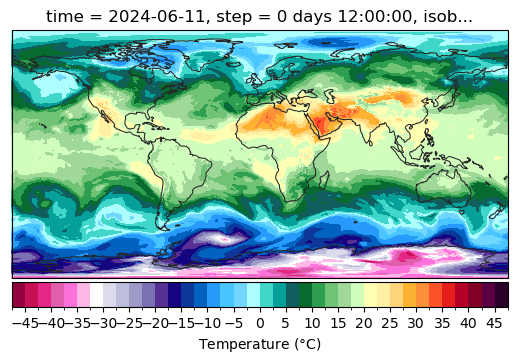

In [42]:
ds = H.xarray(":t:850")
(ds.t - 273.15).plot(
    x="longitude",
    y="latitude",
    ax=EasyMap().ax,
    transform=pc,
    **paint.NWSTemperature.kwargs2,
    cbar_kwargs=paint.NWSTemperature.cbar_kwargs2
    | dict(orientation="horizontal", pad=0.01),
)
ds

### AIFS Ensembles
The AIFS ensemble directories contain both the individual ensemble members and the control run. To address this, the user can pass the keyword argument `get_control` when creating the Herbie object with a value of `True` to access data from the control run.

In [3]:
# AIFS ensemble individual members
H = Herbie("2025-07-02-00", model="aifs", product="enfo", fxx=6)
H.inventory("2t")

✅ Found ┊ model=aifs ┊ product=enfo ┊ 2025-Jul-02 00:00 UTC F06 ┊ GRIB2 @ aws ┊ IDX @ aws


,grib_message,start_byte,end_byte,range,reference_time,valid_time,step,param,levelist,levtype,number,domain,expver,class,type,stream,search_this
119,120,103266930,103890654,103266930-103890654,2025-07-02,2025-07-02 06:00:00,0 days 06:00:00,2t,NaN,sfc,34,g,0001,ai,pf,enfo,:2t:sfc:34:g:0001:ai:pf:enfo
186,187,158285723,158909113,158285723-158909113,2025-07-02,2025-07-02 06:00:00,0 days 06:00:00,2t,NaN,sfc,33,g,0001,ai,pf,enfo,:2t:sfc:33:g:0001:ai:pf:enfo
267,268,224267267,224890367,224267267-224890367,2025-07-02,2025-07-02 06:00:00,0 days 06:00:00,2t,NaN,sfc,32,g,0001,ai,pf,enfo,:2t:sfc:32:g:0001:ai:pf:enfo
329,330,283034283,283657319,283034283-283657319,2025-07-02,2025-07-02 06:00:00,0 days 06:00:00,2t,NaN,sfc,31,g,0001,ai,pf,enfo,:2t:sfc:31:g:0001:ai:pf:enfo
337,338,291249929,291873821,291249929-291873821,2025-07-02,2025-07-02 06:00:00,0 days 06:00:00,2t,NaN,sfc,7,g,0001,ai,pf,enfo,:2t:sfc:7:g:0001:ai:pf:enfo
450,451,385591466,386214503,385591466-386214503,2025-07-02,2025-07-02 06:00:00,0 days 06:00:00,2t,NaN,sfc,30,g,0001,ai,pf,enfo,:2t:sfc:30:g:0001:ai:pf:enfo
509,510,434957178,435581267,434957178-435581267,2025-07-02,2025-07-02 06:00:00,0 days 06:00:00,2t,NaN,sfc,6,g,0001,ai,pf,enfo,:2t:sfc:6:g:0001:ai:pf:enfo
552,553,470979808,471602901,470979808-471602901,2025-07-02,2025-07-02 06:00:00,0 days 06:00:00,2t,NaN,sfc,16,g,0001,ai,pf,enfo,:2t:sfc:16:g:0001:ai:pf:enfo
563,564,480734509,481358971,480734509-481358971,2025-07-02,2025-07-02 06:00:00,0 days 06:00:00,2t,NaN,sfc,3,g,0001,ai,pf,enfo,:2t:sfc:3:g:0001:ai:pf:enfo
577,578,493639241,494262626,493639241-494262626,2025-07-02,2025-07-02 06:00:00,0 days 06:00:00,2t,NaN,sfc,50,g,0001,ai,pf,enfo,:2t:sfc:50:g:0001:ai:pf:enfo


In [4]:
# AIFS ensemble control run
H = Herbie("2025-07-02-00", model="aifs", product="enfo", get_control=True, fxx=6)
H.inventory("2t")

✅ Found ┊ model=aifs ┊ product=enfo ┊ 2025-Jul-02 00:00 UTC F06 ┊ GRIB2 @ aws ┊ IDX @ aws


,grib_message,start_byte,end_byte,range,reference_time,valid_time,step,param,levelist,levtype,number,domain,expver,class,type,stream,search_this
39,40,30703976,31316693,30703976-31316693,2025-07-02,2025-07-02 06:00:00,0 days 06:00:00,2t,NaN,sfc,NaN,g,0001,ai,cf,enfo,:2t:sfc:g:0001:ai:cf:enfo


---

**[Attribution](https://confluence.ecmwf.int/display/DAC/ECMWF+open+data:+real-time+forecasts+from+IFS+and+AIFS#ECMWFopendata:realtimeforecastsfromIFSandAIFS-DownloadASingleFieldWithWgetDownloadasinglefieldwithwget)**

- Copyright statement: Copyright "© 2022 European Centre for Medium-Range Weather Forecasts (ECMWF)".
- Source www.ecmwf.int
- Licence Statement: This data is published under a Creative Commons Attribution 4.0 International (CC BY 4.0). https://creativecommons.org/licenses/by/4.0/
- Disclaimer: ECMWF does not accept any liability whatsoever for any error or omission in the data, their availability, or for any loss or damage arising from their use.
